# 04 - Decision Tree

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.features import get_xy
from src.pipeline import build_model, predict_proba
from src.evaluation import evaluate_and_save, plot_curves, score_at, best_threshold
from sklearn.metrics import average_precision_score

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)

(384548, 13) (81129, 13) (80445, 13)


## Tuning: tree depth and minimum leaf size

In [2]:
grid = [{"max_depth": d, "min_samples_leaf": l} for d in [4, 6, 8, 10] for l in [50, 200]]
results, models = [], []
for params in grid:
    t = time.time()
    m = build_model("decision_tree", **params)
    m.fit(X_train, y_train)
    ap = average_precision_score(y_val, predict_proba(m, X_val))
    results.append({**params, "val_pr_auc": round(ap, 4), "seconds": round(time.time() - t, 1)})
    models.append(m)
tuning = pd.DataFrame(results)
display(tuning.sort_values("val_pr_auc", ascending=False))
i = int(tuning["val_pr_auc"].idxmax())
model, best_params = models[i], grid[i]
print("Best settings:", best_params)

,max_depth,min_samples_leaf,val_pr_auc,seconds
0,4,50,0.0828,3.7
2,6,50,0.0823,4.5
3,6,200,0.0806,3.2
1,4,200,0.0801,3.5
5,8,200,0.0770,5.8
7,10,200,0.0767,6.7
4,8,50,0.0761,5.4
6,10,50,0.0657,6.7


Best settings: {'max_depth': 4, 'min_samples_leaf': 50}


## Evaluate on validation and test

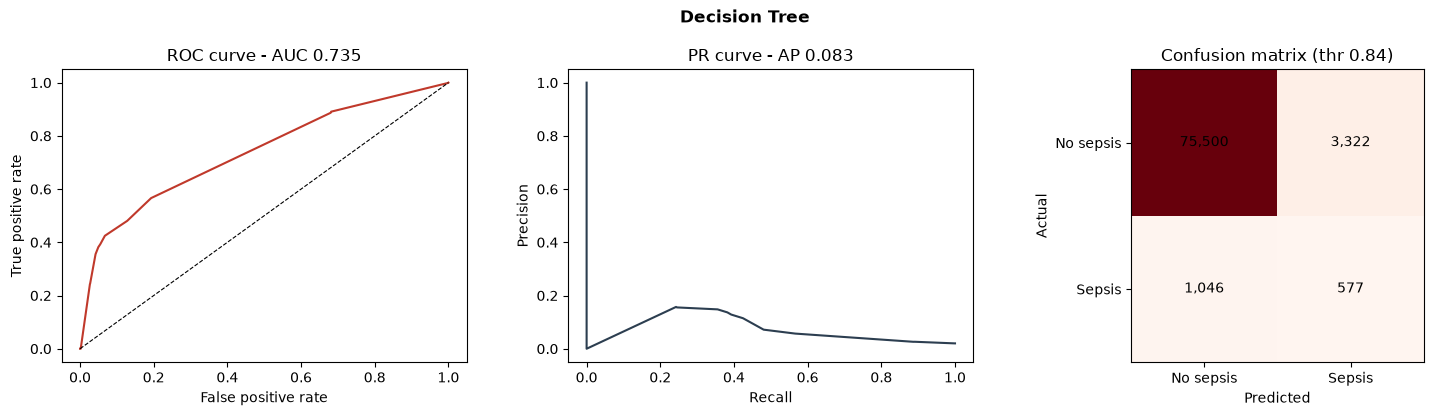

,val,test
roc_auc,0.714,0.735
pr_auc,0.083,0.083
precision,0.153,0.148
recall,0.317,0.356
specificity,0.961,0.958
f1,0.206,0.209
f2,0.261,0.278
balanced_accuracy,0.639,0.657


In [3]:
p_val = predict_proba(model, X_val)
p_test = predict_proba(model, X_test)
res = evaluate_and_save("decision_tree", y_val, p_val, y_test, p_test, extra={"params": best_params, "tuning": tuning.to_dict("records")})
plot_curves(y_test, p_test, "Decision Tree", res["test"]["threshold"])
pd.DataFrame(res).loc[["roc_auc","pr_auc","precision","recall","specificity","f1","f2","balanced_accuracy"], ["val","test"]].round(3)

## Feature importance

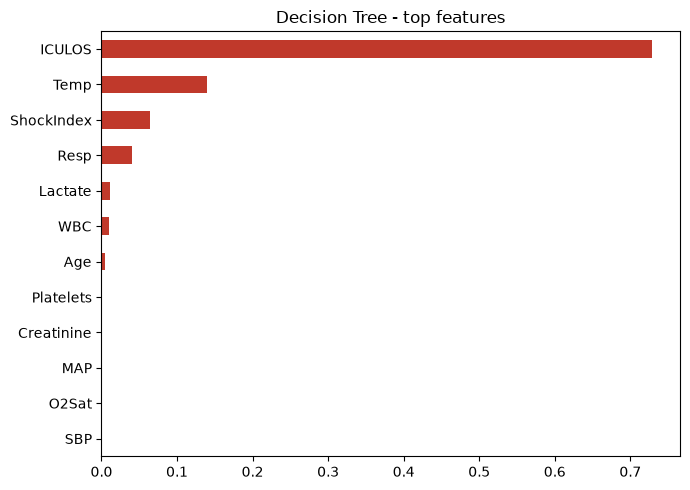

In [4]:
imp = pd.Series(model.named_steps["model"].feature_importances_, index=X_train.columns).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), color="#c0392b"); plt.title("Decision Tree - top features")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "decision_tree_importance.png", dpi=130); plt.show()